## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)


In [48]:

df = pd.read_csv("jobs_in_data.csv")
df.head()


,work_year,job_title,job_category,salary_currency,salary,salary_in_usd,employee_residence,experience_level,employment_type,work_setting,company_location,company_size
0,2023,Data DevOps Engineer,Data Engineering,EUR,88000,95012,Germany,Mid-level,Full-time,Hybrid,Germany,L
1,2023,Data Architect,Data Architecture and Modeling,USD,186000,186000,United States,Senior,Full-time,In-person,United States,M
2,2023,Data Architect,Data Architecture and Modeling,USD,81800,81800,United States,Senior,Full-time,In-person,United States,M
3,2023,Data Scientist,Data Science and Research,USD,212000,212000,United States,Senior,Full-time,In-person,United States,M
4,2023,Data Scientist,Data Science and Research,USD,93300,93300,United States,Senior,Full-time,In-person,United States,M


In [3]:
print("Shape:", df.shape)
df.info()


Shape: (9355, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9355 entries, 0 to 9354
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           9355 non-null   int64 
 1   job_title           9355 non-null   object
 2   job_category        9355 non-null   object
 3   salary_currency     9355 non-null   object
 4   salary              9355 non-null   int64 
 5   salary_in_usd       9355 non-null   int64 
 6   employee_residence  9355 non-null   object
 7   experience_level    9355 non-null   object
 8   employment_type     9355 non-null   object
 9   work_setting        9355 non-null   object
 10  company_location    9355 non-null   object
 11  company_size        9355 non-null   object
dtypes: int64(3), object(9)
memory usage: 877.2+ KB


In [4]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
work_year,9355.0,NaN,NaN,NaN,2022.760449,0.51947,2020.0,2023.0,2023.0,2023.0,2023.0
job_title,9355,125,Data Engineer,2195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_category,9355,10,Data Science and Research,3014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_currency,9355,11,USD,8591,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,9355.0,NaN,NaN,NaN,149927.981293,63608.835387,14000.0,105200.0,143860.0,187000.0,450000.0
salary_in_usd,9355.0,NaN,NaN,NaN,150299.495564,63177.372024,15000.0,105700.0,143000.0,186723.0,450000.0
employee_residence,9355,83,United States,8086,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience_level,9355,4,Senior,6709,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,9355,4,Full-time,9310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_setting,9355,3,In-person,5730,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data Quality Checks

In [54]:

missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)


Series([], dtype: int64)

In [56]:

print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 4014


In [52]:

cat_cols = df.select_dtypes(include="object").columns
for c in cat_cols:
    print(f"{c}: {df[c].nunique()} unique -> {df[c].unique()[:10]}")


job_title: 125 unique -> ['Data DevOps Engineer' 'Data Architect' 'Data Scientist'
 'Machine Learning Researcher' 'Data Engineer' 'Machine Learning Engineer'
 'Data Analyst' 'Analytics Engineer' 'Applied Scientist' 'BI Developer']
job_category: 10 unique -> ['Data Engineering' 'Data Architecture and Modeling'
 'Data Science and Research' 'Machine Learning and AI' 'Data Analysis'
 'Leadership and Management' 'BI and Visualization'
 'Data Quality and Operations' 'Data Management and Strategy'
 'Cloud and Database']
salary_currency: 11 unique -> ['EUR' 'USD' 'GBP' 'CAD' 'AUD' 'PLN' 'BRL' 'TRY' 'CHF' 'SGD']
employee_residence: 83 unique -> ['Germany' 'United States' 'United Kingdom' 'Canada' 'Spain' 'Ireland'
 'South Africa' 'Poland' 'France' 'Czech Republic']
experience_level: 4 unique -> ['Mid-level' 'Senior' 'Executive' 'Entry-level']
employment_type: 4 unique -> ['Full-time' 'Part-time' 'Contract' 'Freelance']
work_setting: 3 unique -> ['Hybrid' 'In-person' 'Remote']
company_location: 

In [50]:

q1, q3 = df["salary_in_usd"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["salary_in_usd"] < lower) | (df["salary_in_usd"] > upper)]
print(f"Potential outliers: {len(outliers)} rows ({len(outliers)/len(df):.1%})")
outliers[["job_title", "experience_level", "salary_in_usd"]].sort_values("salary_in_usd", ascending=False).head(10)


Potential outliers: 158 rows (1.7%)


,job_title,experience_level,salary_in_usd
9157,Research Scientist,Mid-level,450000
7683,Data Analyst,Mid-level,430967
5702,Analytics Engineer,Mid-level,430640
9348,Applied Machine Learning Scientist,Mid-level,423000
9287,Principal Data Scientist,Executive,416000
9351,Data Scientist,Senior,412000
9103,Data Analytics Lead,Senior,405000
1696,Research Scientist,Mid-level,405000
4938,Analytics Engineering Manager,Senior,399880
4267,Machine Learning Engineer,Senior,392000


## 4. Univariate Exploration

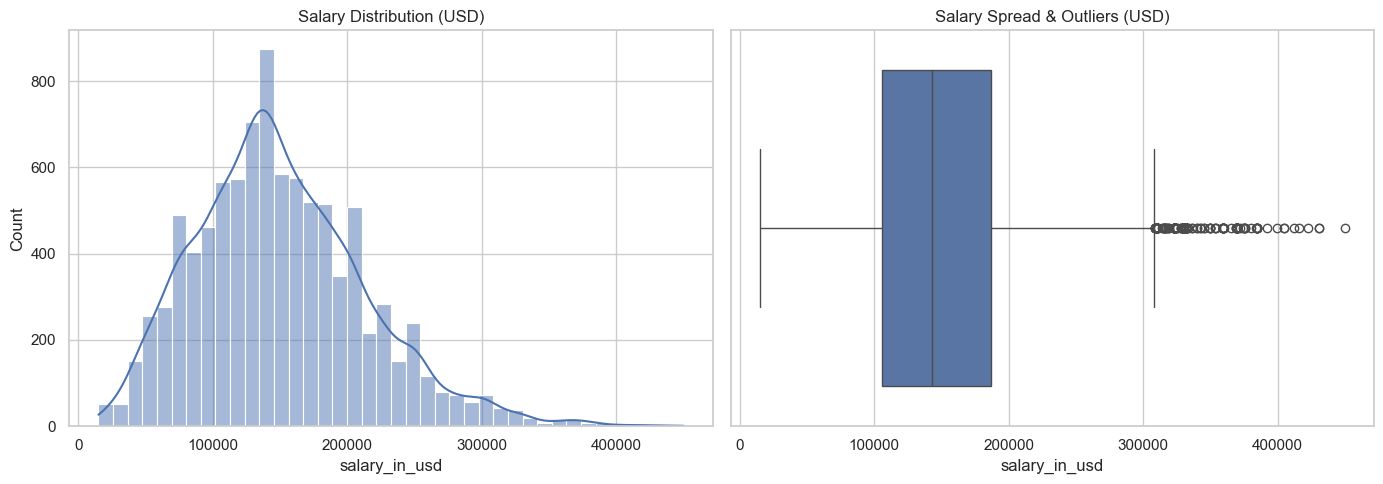

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["salary_in_usd"], bins=40, kde=True, ax=ax[0])
ax[0].set_title("Salary Distribution (USD)")
sns.boxplot(x=df["salary_in_usd"], ax=ax[1])
ax[1].set_title("Salary Spread & Outliers (USD)")
plt.tight_layout()
plt.show()


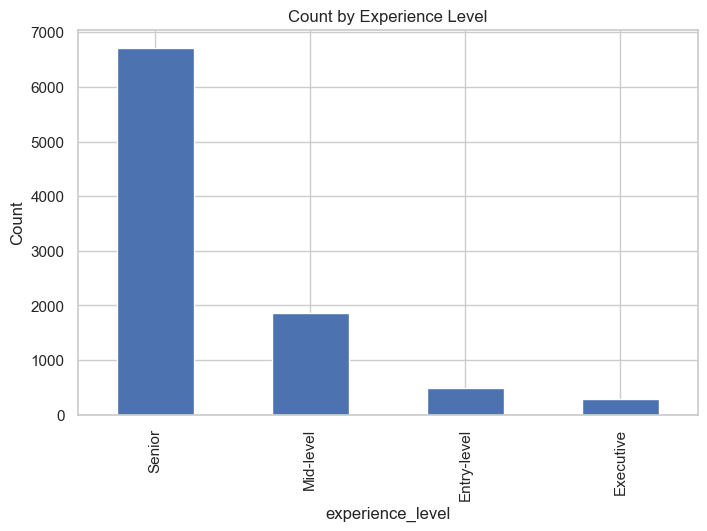

In [13]:
plt.figure(figsize=(8, 5))
df["experience_level"].value_counts().plot(kind="bar")
plt.title("Count by Experience Level")
plt.ylabel("Count")
plt.show()


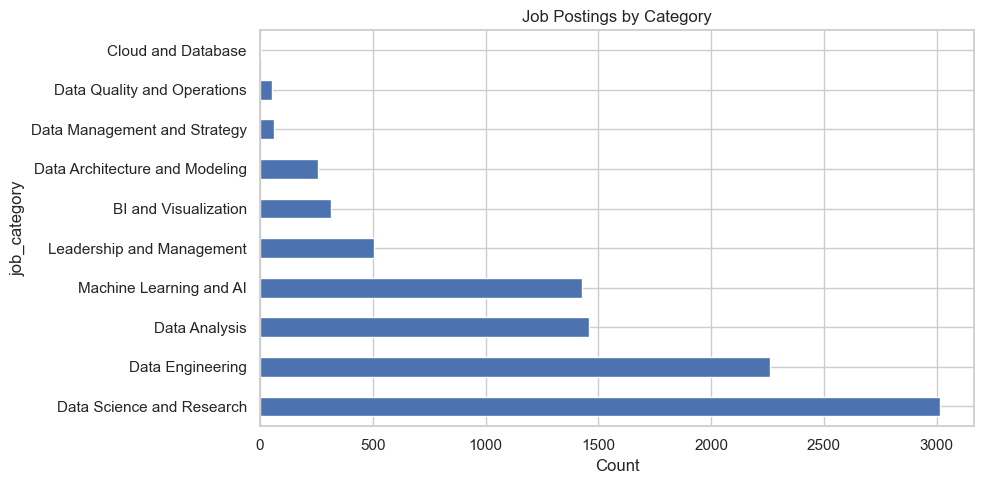

In [14]:
plt.figure(figsize=(10, 5))
df["job_category"].value_counts().plot(kind="barh")
plt.title("Job Postings by Category")
plt.xlabel("Count")
plt.tight_layout()
plt.show()


## 5. Bivariate & Multivariate Analysis

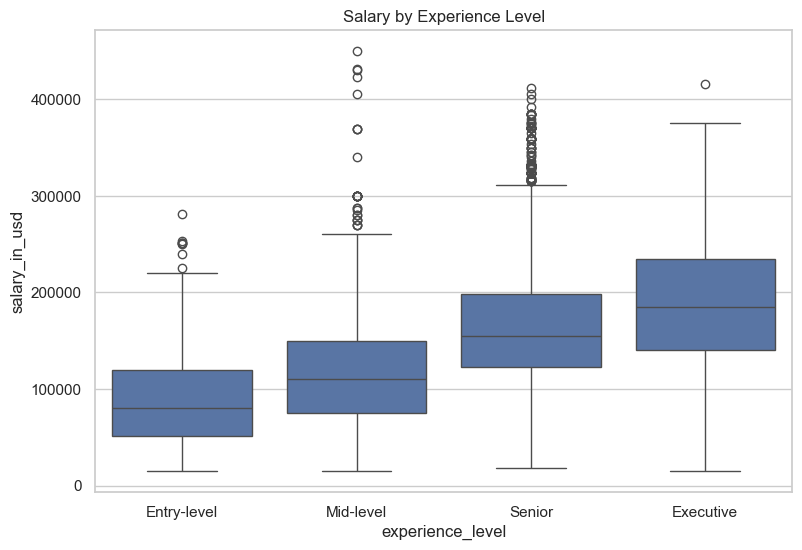

In [16]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x="experience_level", y="salary_in_usd",
            order=["Entry-level", "Mid-level", "Senior", "Executive"])
plt.title("Salary by Experience Level")
plt.show()


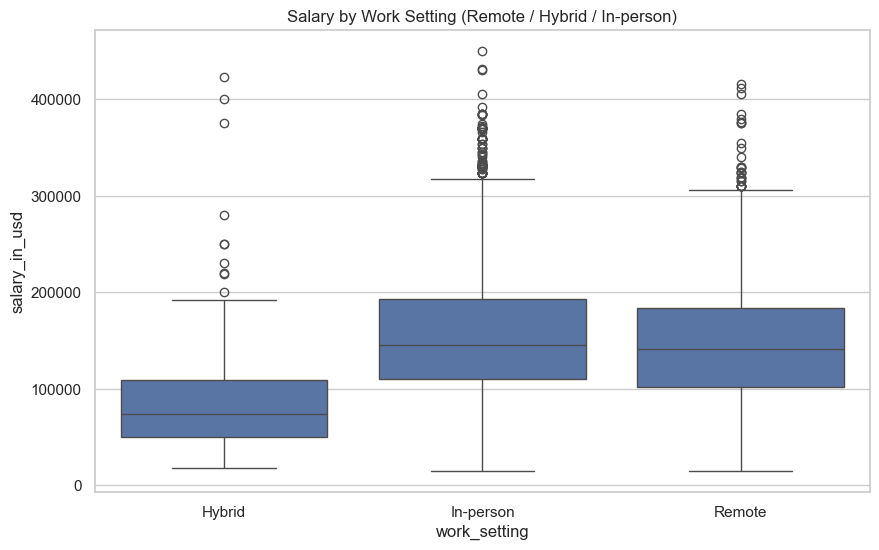

In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="work_setting", y="salary_in_usd")
plt.title("Salary by Work Setting (Remote / Hybrid / In-person)")
plt.show()


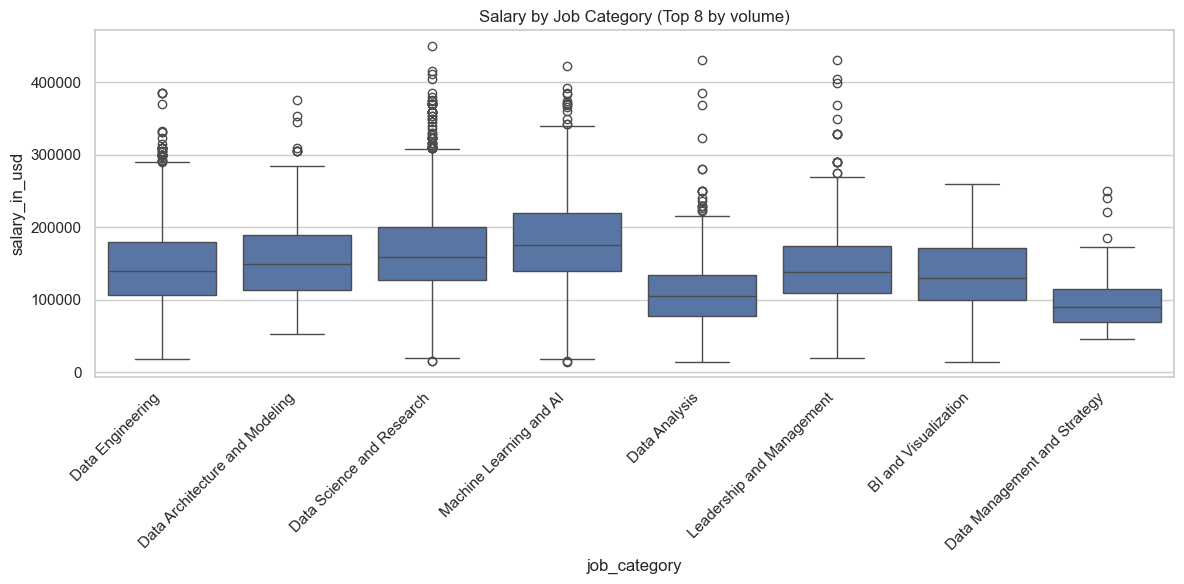

In [23]:
plt.figure(figsize=(12, 6))
top_categories = df["job_category"].value_counts().head(8).index
sns.boxplot(data=df[df["job_category"].isin(top_categories)],
            x="job_category", y="salary_in_usd")
plt.xticks(rotation=45, ha="right")
plt.title("Salary by Job Category (Top 8 by volume)")
plt.tight_layout()
plt.show()


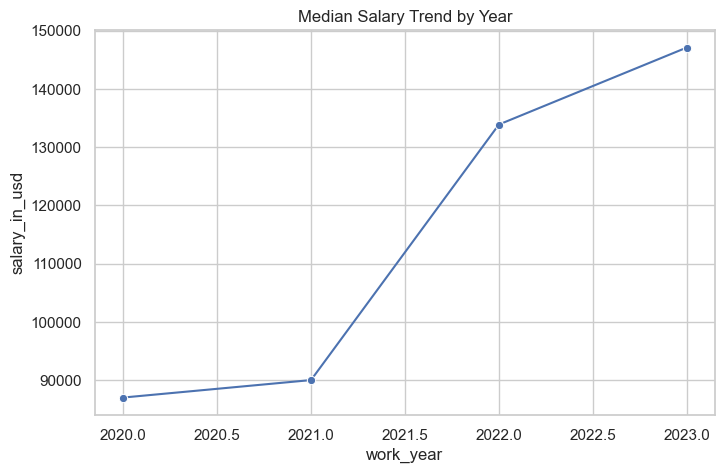

In [27]:
yearly = df.groupby("work_year")["salary_in_usd"].median().reset_index()
plt.figure(figsize=(8, 5))
sns.lineplot(data=yearly, x="work_year", y="salary_in_usd", marker="o")
plt.title("Median Salary Trend by Year")
plt.show()


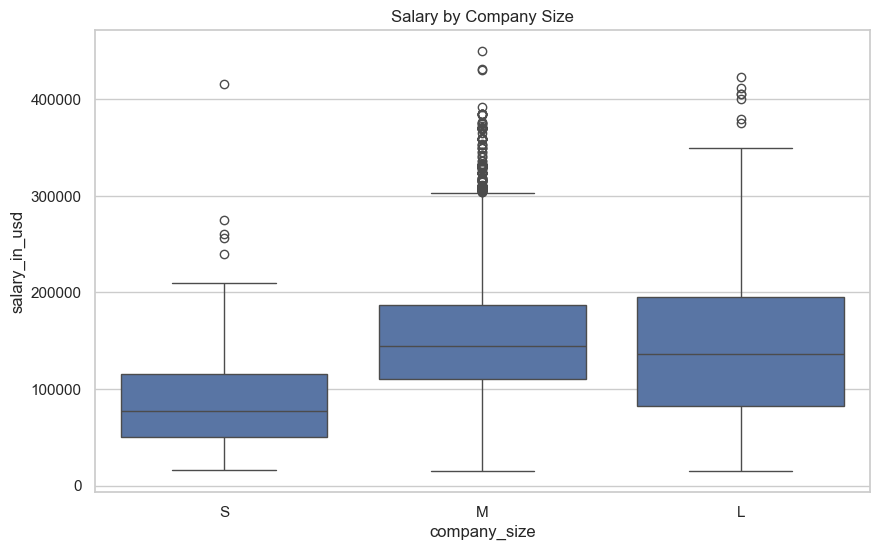

In [28]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="company_size", y="salary_in_usd", order=["S", "M", "L"])
plt.title("Salary by Company Size")
plt.show()


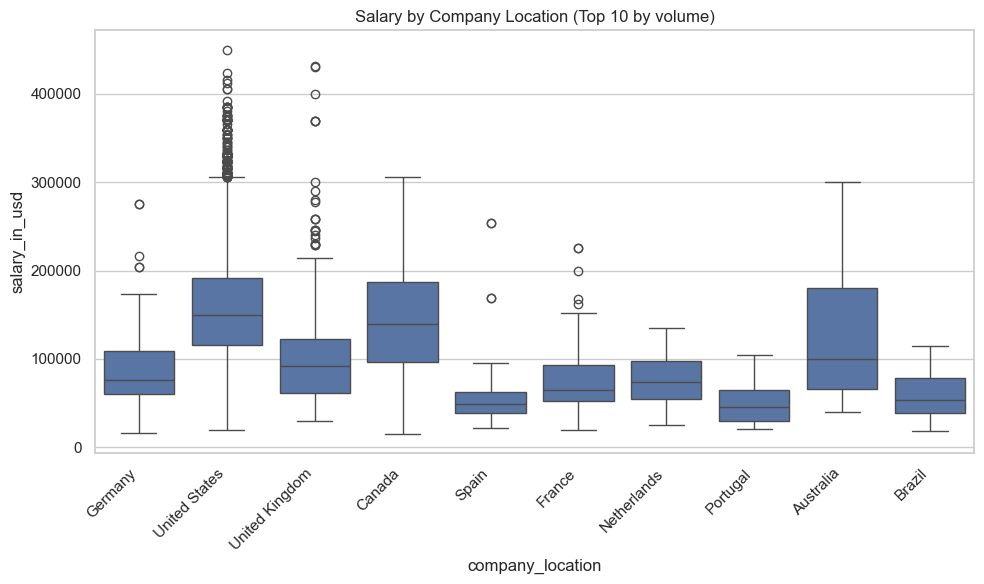

In [29]:
top_locations = df["company_location"].value_counts().head(10).index
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[df["company_location"].isin(top_locations)],
            x="company_location", y="salary_in_usd")
plt.xticks(rotation=45, ha="right")
plt.title("Salary by Company Location (Top 10 by volume)")
plt.tight_layout()
plt.show()


## 6. Hypothesis Testing

**H0:** There is no significant difference in mean salary between fully remote and fully in-person roles.
**H1:** There is a significant difference.

Using an independent-samples t-test (Welch's, unequal variance assumed).


In [33]:
remote = df[df["work_setting"] == "Remote"]["salary_in_usd"]
onsite = df[df["work_setting"] == "In-person"]["salary_in_usd"]

t_stat, p_val = stats.ttest_ind(remote, onsite, equal_var=False)
print(f"t-statistic: {t_stat:.3f}, p-value: {p_val:.5f}")

if p_val < 0.05:
    print("=> Reject H0: statistically significant difference in salary between remote and in-person roles.")
else:
    print("=> Fail to reject H0: no statistically significant difference detected.")


t-statistic: -7.958, p-value: 0.00000
=> Reject H0: statistically significant difference in salary between remote and in-person roles.


In [35]:
# ANOVA across experience levels
groups = [g["salary_in_usd"].values for _, g in df.groupby("experience_level")]
f_stat, p_val_anova = stats.f_oneway(*groups)
print(f"F-statistic: {f_stat:.3f}, p-value: {p_val_anova:.5f}")


F-statistic: 516.382, p-value: 0.00000
